# Chapter 4: Interrogating every column: keep, drop or fix?
*The column audit · also searched as: feature audit, leakage checklist, point in time
correct features*

A leak hides in the column nobody asked about. The audit asks the same five things of every
column before any model sees it, and writes a verdict and a reason beside each, so a
reviewer can disagree with a line instead of with a feeling.

**Who needs the answer.** The solution architect, who decides which feeds the scoring
service may read, and Kavya, who signs the feature list.

**The questions on the way.** What does the audit ask of each column? Which of Kalpa's nine
candidate columns pass? What is the as-of trap? What does the audit hand to the model?

**You will be able to** write the audit table for a new dataset, catch a column that is
rewritten after the fact, and defend each verdict in one line.

## What does the audit ask of each column?
| Ask | Why |
|---|---|
| Which system writes it? | the owner knows when and how it changes |
| When is it written, in days from the prediction moment? | negative means known in time |
| Is it rewritten later? | a value overwritten after the outcome must be read as it stood that morning |
| What is its business reason? | a column nobody can explain is dropped or tested |
| Verdict | keep, drop, or fix (engineer, snapshot, flag) |

Nine invented candidate columns for Kalpa's nudge model follow.

**Predict before you run.** How many of the nine are dropped? (A) 1; (B) 3; (C) 5.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False})
INK, VIOLET, ROSE, GREEN, GREY = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#A9A3D2"

def check(label, ok):
    """Print one line that starts PASS or FAIL, and keep the notebook running either way."""
    print(("PASS  " if ok else "FAIL  ") + label)

cols = pd.DataFrame([   # invented candidate columns for Kalpa's nudge model
    ("days_since_last_order", "orders table", -1, "no", "warm members buy again"),
    ("orders_90d", "orders table", -1, "no", "habit"),
    ("avg_basket_rs", "orders table", -1, "no", "weekly shop against top-up"),
    ("city", "signup form", -400, "no", "stores and delivery differ by city"),
    ("app_visits_7d", "app events", -1, "no", "intent shows before an order"),
    ("loyalty_tier", "loyalty service", -1, "yes", "perks change behaviour"),
    ("member_id", "signup form", -400, "no", ""),
    ("coupon_redeemed", "checkout", 3, "no", "uses the nudge coupon"),
    ("settlement_status", "payments feed", 12, "no", "payment cleared"),
], columns=["column", "written by", "written_day", "rewritten later", "business reason"])

def verdict(r):
    if r["written_day"] > 0:
        return "drop: written after the nudge"
    if not r["business reason"]:
        return "drop: no reason"
    if r["rewritten later"] == "yes":
        return "fix: read the snapshot as of the nudge morning"
    return "keep"
cols["verdict"] = cols.apply(verdict, axis=1)
cols

,column,written by,written_day,rewritten later,business reason,verdict
0,days_since_last_order,orders table,-1,no,warm members buy again,keep
1,orders_90d,orders table,-1,no,habit,keep
2,avg_basket_rs,orders table,-1,no,weekly shop against top-up,keep
3,city,signup form,-400,no,stores and delivery differ by city,keep
4,app_visits_7d,app events,-1,no,intent shows before an order,keep
5,loyalty_tier,loyalty service,-1,yes,perks change behaviour,fix: read the snapshot as of the nudge morning
6,member_id,signup form,-400,no,,drop: no reason
7,coupon_redeemed,checkout,3,no,uses the nudge coupon,drop: written after the nudge
8,settlement_status,payments feed,12,no,payment cleared,drop: written after the nudge


**What happened.** B. Three are dropped. `coupon_redeemed` and `settlement_status` are
written after the nudge, the first on the day the coupon is used, which is the outcome
itself. `member_id` has no reason: an identifier is a key, and it would only carry signal
by accident (for example, if ids are issued in signup order, it becomes cohort age in
disguise, and cohort age should then be engineered openly). `loyalty_tier` is kept with a
fix, explained next.

## What is the as-of trap?
`loyalty_tier` is written every night and overwritten in place. A member who bought three
times after the nudge was upgraded to Gold in December. The warehouse today says Gold; on
the nudge morning it said Silver.

**Predict before you run.** If training reads today's tier, the Gold members in training are
(A) a fair mix; (B) mostly members who bought after the nudge, so the tier leaks the outcome.

In [2]:
tiers = pd.DataFrame({   # invented: two members' tier today and as of the nudge morning
    "member": ["M04", "M07"], "bought_90d": [0, 1],
    "tier_today": ["Silver", "Gold"], "tier_as_of_nudge_morning": ["Silver", "Silver"]})
tiers

,member,bought_90d,tier_today,tier_as_of_nudge_morning
0,M04,0,Silver,Silver
1,M07,1,Gold,Silver


**What happened.** B. M07 bought, was upgraded, and today's table says Gold; a model trained
on today's tier learns "Gold buys", which was written by the purchase. The fix is a snapshot
(an as-of join): read each value as it stood on the prediction morning. The question to the
owner is "is this field ever overwritten?", and a yes means the audit asks for history.

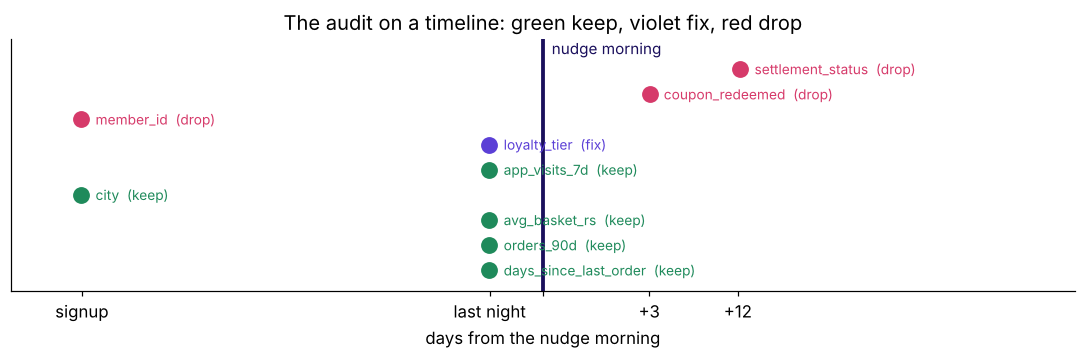

In [3]:
colour = {"keep": GREEN, "fix": VIOLET, "drop": ROSE}
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.axvline(0, color=INK, lw=2.5); ax.text(0.05, 8.6, "nudge morning", color=INK, fontsize=10)
for i, r in cols.iterrows():
    x = np.sign(r["written_day"]) * np.log10(abs(r["written_day"]) + 1)
    c = colour[r["verdict"].split(":")[0]]
    ax.plot(x, i, "o", color=c, ms=10)
    ax.text(x + (0.08 if x < 2 else -0.08), i, f"{r['column']}  ({r['verdict'].split(':')[0]})",
            va="center", fontsize=9, color=c, ha="left" if x < 2 else "right")
ax.set_yticks([]); ax.set_xlim(-3, 3); ax.set_ylim(-0.8, 9.2)
ax.set_xticks([-2.6, -0.3, 0, 0.6, 1.1]); ax.set_xticklabels(["signup", "last night", "", "+3", "+12"])
ax.set_xlabel("days from the nudge morning")
ax.set_title("The audit on a timeline: green keep, violet fix, red drop")
plt.tight_layout(); plt.show()

In [4]:
check("three columns are dropped", int(cols["verdict"].str.startswith("drop").sum()) == 3)
check("every column written after the nudge is dropped",
      cols.loc[cols["written_day"] > 0, "verdict"].str.startswith("drop").all())
check("every kept column has a business reason",
      (cols.loc[cols["verdict"] == "keep", "business reason"].str.len() > 0).all())

PASS  three columns are dropped
PASS  every column written after the nudge is dropped
PASS  every kept column has a business reason


## What are the rules, and what flips each one?
1. Audit every column before any model sees it, the boring ones first; an identifier or a
   timestamp is where leaks hide.
2. Ask the owner whether a field is overwritten; a yes means the model reads the snapshot
   as of the prediction moment, never today's value.
3. Drop a column with no business reason; keep it only if a fair test shows signal that
   survives the audit.
4. Write the verdict and the reason on one line per column, so a reviewer argues with a line.

Chapter 5 asks what the model's importance chart can say about the columns that survive.